# Лабораторная работа №3
## Классическое машинное обучение в NLP: векторизация, классификация, полнотекстовый поиск и тематическое моделирование

**Цель работы:** попробовать классические методы NLP на отзывах покупателей. Превратить тексты в числовые признаки, обучить классификаторы, сделать поиск по отзывам и выделить основные темы.

Продолжаем работать с **Amazon Product Reviews**, как и в предыдущих лабораторных. Для сопоставимости оставляем подготовку данных из ЛР №2: убираем пропуски, повторяющиеся тексты и отзывы, у которых один и тот же текст сопровождается разными оценками. После очистки в нашем корпусе 907 уникальных отзывов.

**Что будем предсказывать?** По тексту отзыва попробуем определить, положительно, нейтрально или отрицательно покупатель оценил товар. Готовых меток тональности в нашем CSV нет, зато есть `reviews.rating` — оценка, которую пользователь поставил товару на Amazon по шкале от 1 до 5. Из неё мы сами сформируем три класса: `negative`, `neutral` и `positive`.

Оценка товара — это ориентир, а не безошибочная разметка настроения текста. Человек может поставить 4 балла и при этом подробно описывать недостатки. Такие случаи особенно интересны при разборе ошибок.

**План работы.** Сначала очистим отзывы и разделим их на обучающую и тестовую выборки. Затем сравним BoW и TF-IDF, обучим две модели и посмотрим, на каких отзывах они ошибаются. После этого построим поиск BM25 по всему корпусу и попробуем выделить основные темы с помощью LDA.

In [69]:
import json
import math
import re
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

In [70]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, precision_recall_fscore_support)
from gensim.corpora import Dictionary
from gensim.models import LdaModel, CoherenceModel
from gensim.utils import simple_preprocess
from gensim.parsing.preprocessing import STOPWORDS as GENSIM_STOPWORDS

In [71]:
SEED = 42
np.random.seed(SEED)
DATA_DIR = Path("data")
RESULTS_DIR = Path("results_lab3")
FIG_DIR = RESULTS_DIR / "figures"
DATA_DIR.mkdir(exist_ok=True, parents=True)
FIG_DIR.mkdir(exist_ok=True, parents=True)
LABELS = ["negative", "neutral", "positive"]
VECTORIZER_PARAMS = dict(ngram_range=(1, 2), min_df=2, max_df=0.95, lowercase=True, strip_accents="unicode")
pd.set_option("display.max_colwidth", 300)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", None)

Для графиков будем использовать одни и те же цвета: отрицательные отзывы покажем коралловым, нейтральные — золотистым, положительные — бирюзовым. Так будет проще сравнивать результаты на разных рисунках.

In [72]:
INK, MUTED, GRID, PAPER = "#233249", "#64748B", "#E2E8EF", "#FAFBFD"
TEAL, CORAL, GOLD, BLUE = "#168F87", "#D06B60", "#B88A35", "#5478A7"
GROUP_COLORS = {"negative": CORAL, "neutral": GOLD, "positive": TEAL}

sns.set_theme(style="white", font="DejaVu Sans")

plt.rcParams.update({"figure.facecolor": PAPER, "axes.facecolor": PAPER,
                     "text.color": INK, "axes.labelcolor": INK,
                     "axes.edgecolor": GRID, "axes.grid": True,
                     "grid.color": GRID, "figure.dpi": 120})

### Шаг 1. Загрузка датасета

Используем тот же `7817_1.csv`, что и раньше. Если файла нет в папке `data`, попробуем найти его через `kagglehub`. Пока оставляем тексты в исходном виде: при анализе ошибок важно видеть, что именно написал покупатель.

In [73]:
candidates = [DATA_DIR / "7817_1.csv", Path("7817_1.csv")]
csv_path = next((path for path in candidates if path.exists()), None)

if csv_path is None:
    import kagglehub
    dataset_dir = kagglehub.dataset_download("yasserh/amazon-product-reviews-dataset")
    csv_path = Path(dataset_dir) / "7817_1.csv"

if not csv_path.exists():
    raise FileNotFoundError(f"Не найден файл датасета: {csv_path}")

print("Источник:", csv_path)

Источник: C:\Users\sonyb\.cache\kagglehub\datasets\yasserh\amazon-product-reviews-dataset\versions\1\7817_1.csv


In [74]:
raw = pd.read_csv(csv_path, low_memory=False)
required_columns = {"reviews.text", "reviews.rating"}
assert required_columns.issubset(raw.columns), "В CSV отсутствуют необходимые колонки"

print("Размер исходного датасета:", raw.shape)
display(raw[["reviews.text", "reviews.rating"]].head(3))

Размер исходного датасета: (1597, 27)


,reviews.text,reviews.rating
0,"I initially had trouble deciding between the paperwhite and the voyage because reviews more or less said the same thing: the paperwhite is great, but if you have spending money, go for the voyage.Fortunately, I had friends who owned each, so I ended up buying the paperwhite on this basis: both m...",5.0
1,"Allow me to preface this with a little history. I am (was) a casual reader who owned a Nook Simple Touch from 2011. I've read the Harry Potter series, Girl with the Dragon Tattoo series, 1984, Brave New World, and a few other key titles. Fair to say my Nook did not get as much use as many others...",5.0
2,I am enjoying it so far. Great for reading. Had the original Fire since 2012. The Fire used to make my eyes hurt if I read too long. Haven't experienced that with the Paperwhite yet.,4.0


#### Оставим нужные столбцы

Нам нужны текст отзыва и оценка покупателя. Для удобства назовём их `Text` и `Score`. Сохраним также номер исходной строки (`source_row`), чтобы при необходимости можно было найти отзыв в первоначальном файле.

In [75]:
frame = raw[["reviews.text", "reviews.rating"]].rename(
    columns={"reviews.text": "Text", "reviews.rating": "Score"}).copy()
frame["source_row"] = np.arange(len(raw))

prep_log = [{"Stage": "Исходные строки", "Rows": len(frame)}]

In [76]:
frame = frame.dropna(subset=["Text", "Score"]).copy()
prep_log.append({"Stage": "Без пропусков", "Rows": len(frame)})
frame["Text"] = frame["Text"].astype(str).str.strip()
frame["Score"] = pd.to_numeric(frame["Score"], errors="coerce")

Оставляем только непустые отзывы с целой оценкой от 1 до 5. Сначала проверяем допустимые значения, а уже потом переводим их в `int`. Иначе оценка вроде 4.5 могла бы незаметно превратиться в 4.

In [77]:
frame = frame.loc[frame["Text"].ne("") & frame["Score"].isin([1,2,3,4,5])].copy()
frame["Score"] = frame["Score"].astype(int)
prep_log.append({"Stage": "Валидный текст и рейтинг", "Rows": len(frame)})

Бывает, что один и тот же текст встречается с разными оценками. Непонятно, какую из них считать правильной, поэтому такие записи лучше исключить целиком. Остальные одинаковые тексты оставим в одном экземпляре.

In [78]:
rating_variation = frame.groupby("Text")["Score"].nunique()
conflicting_texts = set(rating_variation[rating_variation > 1].index)
conflicts = frame.loc[frame["Text"].isin(conflicting_texts)].copy()

print("Текстов с конфликтующими оценками:", len(conflicting_texts))
display(conflicts[["source_row", "Text", "Score"]].head(6))

Текстов с конфликтующими оценками: 1


,source_row,Text,Score
342,342,Read more,5
366,366,Read more,4
791,791,Read more,5
807,807,Read more,4


In [79]:
frame = frame.loc[~frame["Text"].isin(conflicting_texts)].copy()
prep_log.append({"Stage": "Без конфликтующих текстов", "Rows": len(frame)})
frame = frame.drop_duplicates(subset="Text", keep="first").reset_index(drop=True)
prep_log.append({"Stage": "Уникальные тексты", "Rows": len(frame)})
display(pd.DataFrame(prep_log))

,Stage,Rows
0,Исходные строки,1597
1,Без пропусков,1177
2,Валидный текст и рейтинг,1177
3,Без конфликтующих текстов,1173
4,Уникальные тексты,907


#### Как из оценки покупателя получить тональность

В исходном датасете есть оценка товара от 1 до 5, но нет отдельного столбца с тональностью текста. В задании разрешено выбрать задачу классификации под свой датасет, поэтому для нашей работы используем простое правило:

| Оценка покупателя (`Score`) | Класс (`Sentiment`) | Как будем называть |
|---|---|---|
| 1–2 | `negative` | отрицательный отзыв |
| 3 | `neutral` | нейтральный отзыв |
| 4–5 | `positive` | положительный отзыв |

In [80]:
frame["Sentiment"] = pd.cut(
    frame["Score"], bins=[0,2,3,5], labels=LABELS
).astype(str)

frame["doc_id"] = frame["source_row"].map(lambda x: f"review_{x:05d}")

assert frame["Text"].is_unique and frame["doc_id"].is_unique
assert set(frame["Sentiment"]) == set(LABELS)

In [81]:
print("Размер итогового корпуса:", frame.shape)
display(frame["Sentiment"].value_counts().reindex(LABELS).rename("Количество").to_frame())
display(frame[["doc_id", "Text", "Score", "Sentiment"]].head(3))

Размер итогового корпуса: (907, 5)


,Количество
Sentiment,
negative,72
neutral,70
positive,765


,doc_id,Text,Score,Sentiment
0,review_00000,"I initially had trouble deciding between the paperwhite and the voyage because reviews more or less said the same thing: the paperwhite is great, but if you have spending money, go for the voyage.Fortunately, I had friends who owned each, so I ended up buying the paperwhite on this basis: both m...",5,positive
1,review_00001,"Allow me to preface this with a little history. I am (was) a casual reader who owned a Nook Simple Touch from 2011. I've read the Harry Potter series, Girl with the Dragon Tattoo series, 1984, Brave New World, and a few other key titles. Fair to say my Nook did not get as much use as many others...",5,positive
2,review_00002,I am enjoying it so far. Great for reading. Had the original Fire since 2012. The Fire used to make my eyes hurt if I read too long. Haven't experienced that with the Paperwhite yet.,4,positive


Посмотрим, сколько отзывов получилось в каждом классе. Это важно: если одного класса гораздо больше, модель может научиться предсказывать почти всегда его и всё равно показывать высокую Accuracy.

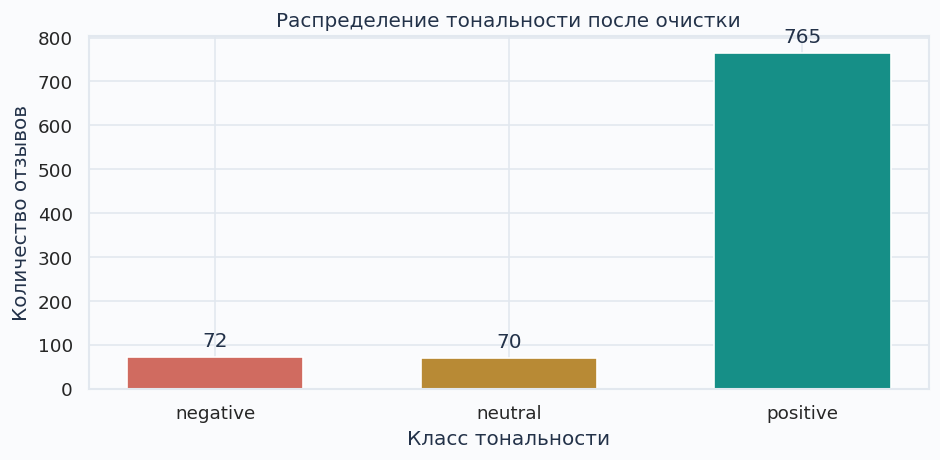

In [82]:
class_counts = frame["Sentiment"].value_counts().reindex(LABELS)
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(LABELS, class_counts, color=[GROUP_COLORS[x] for x in LABELS], width=0.6)
ax.bar_label(bars, padding=4)
ax.set(xlabel="Класс тональности", ylabel="Количество отзывов",
       title="Распределение тональности после очистки")
fig.tight_layout()
fig.savefig(FIG_DIR / "class_distribution.png", dpi=180, bbox_inches="tight")
plt.show()

In [83]:
frame.to_csv(RESULTS_DIR / "corpus.csv", index=False, encoding="utf-8-sig")
if not conflicts.empty:
    conflicts.to_csv(RESULTS_DIR / "excluded_conflicts.csv",
                     index=False, encoding="utf-8-sig")
if len(frame) != 907:
    print("Размер отличается от версии второй лабораторной (907): проверь исходный CSV.")

#### Что получилось после очистки

В исходном файле было **1 597 строк**. После удаления пропусков осталось 1 177, после исключения противоречивых оценок — 1 173, а после удаления повторов — **907 разных отзывов**.

Положительных отзывов оказалось **765**, отрицательных — **72**, нейтральных — **70**. Получается, что примерно 84% текстов относятся к положительному классу. Поэтому дальше важно смотреть не только на общий процент правильных ответов, но и на то, как модели справляются с двумя небольшими группами.

### Шаг 2. Представление текстов: Bag of Words и TF-IDF

Разделим отзывы на две части: **80% для обучения** и **20% для итоговой проверки**. `stratify` поможет сохранить похожие доли трёх классов в обеих выборках. Для воспроизводимости используем `random_state=42`.

Словарь и статистики векторизаторов будем строить **только по Train**. Тестовые отзывы модель должна увидеть как новые данные.

In [84]:
train_df, test_df = train_test_split(
    frame, test_size=0.20, random_state=SEED, stratify=frame["Sentiment"]
)

X_train, X_test = train_df["Text"], test_df["Text"]
y_train, y_test = train_df["Sentiment"], test_df["Sentiment"]

print("Train:", len(train_df), "| Test:", len(test_df))

Train: 725 | Test: 182


In [85]:
class_split = pd.DataFrame({
    "Train": y_train.value_counts(), "Test": y_test.value_counts()
}).reindex(LABELS)

display(class_split)

assert set(train_df["doc_id"]).isdisjoint(test_df["doc_id"])
assert set(X_train).isdisjoint(set(X_test))

,Train,Test
Sentiment,,
negative,58,14
neutral,56,14
positive,611,154


#### Bag of Words

Здесь текст представляется через количество встреченных слов и пар соседних слов (биграмм). Например, сочетание `battery life` считается отдельным признаком. Метод простой, но не понимает смысл и не учитывает порядок слов дальше заданных n-грамм.

In [86]:
bow = CountVectorizer(**VECTORIZER_PARAMS)
X_train_bow = bow.fit_transform(X_train)
X_test_bow = bow.transform(X_test)

print("BoW Train:", X_train_bow.shape, "| Test:", X_test_bow.shape)

BoW Train: (725, 13450) | Test: (182, 13450)


В этой ячейке `fit_transform()` применяется к Train, а для Test используется только `transform()`. Если включить тестовые отзывы в построение словаря, проверка качества перестанет быть независимой.

#### TF-IDF

Теперь учтём не только число появлений слова, но и его распространённость по отзывам. Слова, встречающиеся почти везде, будут менее информативными. Параметр `sublinear_tf=True` смягчает влияние многократных повторений одного слова.

In [87]:
tfidf = TfidfVectorizer(**VECTORIZER_PARAMS, sublinear_tf=True)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF Train:", X_train_tfidf.shape, "| Test:", X_test_tfidf.shape)

TF-IDF Train: (725, 13450) | Test: (182, 13450)


In [88]:
assert set(bow.vocabulary_) == set(tfidf.vocabulary_)
assert X_train_bow.shape == X_train_tfidf.shape
assert X_test_bow.shape == X_test_tfidf.shape

print("Число общих признаков:", len(bow.vocabulary_))

Число общих признаков: 13450


Сравним размеры получившихся матриц. У BoW и TF-IDF одинаковые настройки отбора слов, поэтому набор признаков должен совпасть. Разница — в значениях: у BoW это частоты, у TF-IDF — веса.

In [89]:
vector_dims = pd.DataFrame([
    {"Модель": name, "Train": str(xtr.shape), "Test": str(xte.shape),
     "Признаков": xtr.shape[1], "Плотность Train, %": 100 * xtr.nnz / np.prod(xtr.shape)}
    for name, xtr, xte in [("BoW", X_train_bow, X_test_bow),
                            ("TF-IDF", X_train_tfidf, X_test_tfidf)]
])

display(vector_dims.round(4))
vector_dims.to_csv(RESULTS_DIR / "vector_dimensions.csv", index=False, encoding="utf-8-sig")

,Модель,Train,Test,Признаков,"Плотность Train, %"
0,BoW,"(725, 13450)","(182, 13450)",13450,0.8657
1,TF-IDF,"(725, 13450)","(182, 13450)",13450,0.8657


Возьмём один отзыв и посмотрим на десять признаков с самым большим весом TF-IDF. Так будет нагляднее, какие слова для этого текста оказались наиболее характерными.

In [90]:
example_idx = 0
features = np.array(tfidf.get_feature_names_out())
row = X_train_tfidf[example_idx]
top = np.argsort(row.data)[::-1][:10]
example_features = pd.DataFrame({"Термин": features[row.indices[top]],
                                 "TF-IDF": np.round(row.data[top], 4)})
display(example_features)

,Термин,TF-IDF
0,new unit,0.1972
1,like new,0.1885
2,unit,0.1666
3,discount,0.1466
4,it like,0.1383
5,brand new,0.1213
6,new,0.1198
7,received,0.1152
8,brand,0.1152
9,echo dot,0.1138


#### Что получилось с векторизацией

В сохранённом запуске мы получили **725 отзывов в Train** и **182 в Test**. Оба способа представления дали **13 450 признаков** — это ожидаемо, потому что правила построения словаря одинаковые.

Матрицы оказались очень разрежёнными: лишь около 0,87% элементов обучающей матрицы ненулевые. Для классификации дальше используем TF-IDF, как сказано в задании.

### Шаг 3. Обучение двух классификаторов

Сравним **Logistic Regression** и **Linear SVM**. Обе модели подходят для разрежённых текстовых признаков. Поскольку положительных отзывов намного больше, зададим `class_weight="balanced"`, чтобы ошибки на редких классах учитывались сильнее.

In [91]:
model_specs = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced", max_iter=3000, C=1.0, random_state=SEED),
    "Linear SVM": LinearSVC(
        class_weight="balanced", C=1.0, max_iter=10000, random_state=SEED),
}

#### Выберем модель без подсказок из Test

Сравним алгоритмы с помощью трёхблочной кросс-валидации на обучающей выборке. На каждом разбиении TF-IDF будет заново обучаться внутри `Pipeline`. Так проверочные части фолдов не повлияют на словарь и IDF.

In [92]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
cv_records = []
for name, estimator in model_specs.items():
    pipe = Pipeline([("tfidf", TfidfVectorizer(**VECTORIZER_PARAMS, sublinear_tf=True)),
                     ("classifier", estimator)])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv,
                             scoring="f1_macro", n_jobs=1)
    cv_records.append({"Модель": name, "CV Macro F1 mean": scores.mean(),
                       "CV Macro F1 std": scores.std(),
                       "По фолдам": np.round(scores, 4).tolist()})

In [93]:
cv_table = pd.DataFrame(cv_records).sort_values("CV Macro F1 mean", ascending=False)
display(cv_table)
selected_model_name = str(cv_table.iloc[0]["Модель"])

print("Лучшая модель по Train CV:", selected_model_name)

,Модель,CV Macro F1 mean,CV Macro F1 std,По фолдам
0,Logistic Regression,0.411293,0.039199,"[0.3591, 0.4211, 0.4536]"
1,Linear SVM,0.380444,0.041261,"[0.3381, 0.3669, 0.4364]"


Лучшая модель по Train CV: Logistic Regression


Теперь обучим обе модели на всех отзывах Train и получим прогнозы для Test. На Test ничего не дообучаем — это наша независимая проверка.

In [94]:
fitted_models = {}

for name, spec in model_specs.items():
    model = clone(spec)
    model.fit(X_train_tfidf, y_train)
    fitted_models[name] = model

predictions = {name: model.predict(X_test_tfidf) for name, model in fitted_models.items()}

#### Итог обучения

В сохранённом запуске по среднему Macro F1 на кросс-валидации лучше оказалась **Logistic Regression**. Эту модель мы выбрали по Train, а тестовые результаты используем уже для оценки качества, а не для подбора победителя.

### Шаг 4. Оценка классификации

Посчитаем **Macro Precision, Macro Recall и Macro F1**, как требует задание. Эти показатели сначала рассчитываются отдельно для каждого класса, а затем усредняются: отрицательные, нейтральные и положительные отзывы получают одинаковый вес.

Для сравнения добавим **Accuracy** и простую базовую модель, которая всегда отвечает `positive`. Так станет видно, насколько полезнее наши алгоритмы обычного выбора самого частого класса.

In [95]:
def metric_record(y_true, y_pred, model_name):
    p, r, f, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=LABELS, average="macro", zero_division=0)

    return {"Модель": model_name, "Macro Precision": float(p),
            "Macro Recall": float(r), "Macro F1": float(f),
            "Accuracy": float(accuracy_score(y_true, y_pred))}

In [96]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train_tfidf, y_train)
baseline_pred = dummy.predict(X_test_tfidf)

metrics_table = pd.DataFrame(
    [metric_record(y_test, baseline_pred, "Majority baseline")]
    + [metric_record(y_test, pred, name) for name, pred in predictions.items()]
).sort_values("Macro F1", ascending=False).reset_index(drop=True)

In [97]:
metric_cols = ["Macro Precision", "Macro Recall", "Macro F1", "Accuracy"]
display(metrics_table.style.format({col: "{:.3f}" for col in metric_cols}))
metrics_table.to_csv(RESULTS_DIR / "classification_metrics.csv", index=False, encoding="utf-8-sig")

,Модель,Macro Precision,Macro Recall,Macro F1,Accuracy
0,Logistic Regression,0.685,0.491,0.527,0.863
1,Linear SVM,0.953,0.405,0.436,0.863
2,Majority baseline,0.282,0.333,0.306,0.846


Посмотрим метрики отдельно для каждого класса. Особенно интересно, сколько отрицательных и нейтральных отзывов модели действительно находят, а не просто относят к положительным.

In [98]:
for name, pred in predictions.items():
    print("\n", "="*14, name, "="*14)
    print(classification_report(y_test, pred, labels=LABELS, zero_division=0))


 ============== Logistic Regression ==============
              precision    recall  f1-score   support

    negative       0.50      0.36      0.42        14
     neutral       0.67      0.14      0.24        14
    positive       0.89      0.97      0.93       154

    accuracy                           0.86       182
   macro avg       0.68      0.49      0.53       182
weighted avg       0.84      0.86      0.84       182


 ============== Linear SVM ==============
              precision    recall  f1-score   support

    negative       1.00      0.14      0.25        14
     neutral       1.00      0.07      0.13        14
    positive       0.86      1.00      0.92       154

    accuracy                           0.86       182
   macro avg       0.95      0.40      0.44       182
weighted avg       0.88      0.86      0.81       182



#### Матрицы ошибок

По строкам отложим настоящие метки, полученные из оценок покупателей, а по столбцам — прогнозы модели. Числа на диагонали показывают правильные ответы. Всё вне диагонали — случаи, которые стоит разобрать.

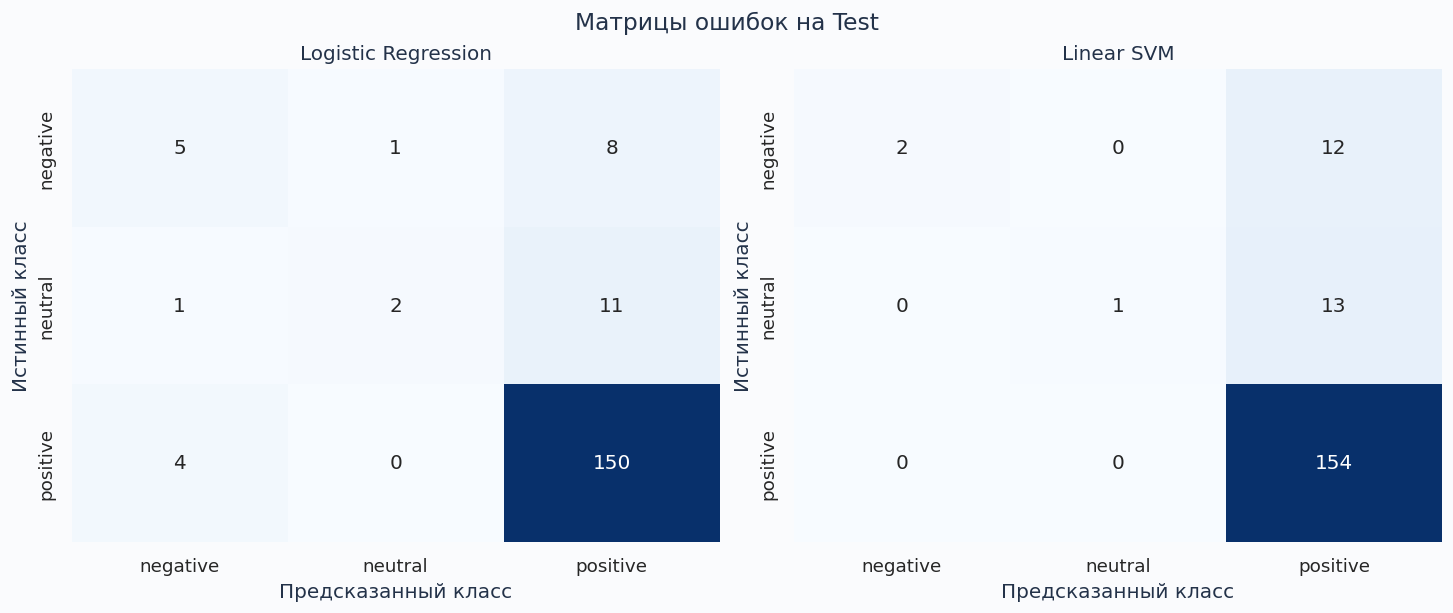

In [99]:
fig, axes = plt.subplots(1, len(predictions), figsize=(12, 5), constrained_layout=True)
for ax, (name, pred) in zip(np.ravel(axes), predictions.items()):
    cm = confusion_matrix(y_test, pred, labels=LABELS)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=LABELS, yticklabels=LABELS, ax=ax)
    ax.set(title=name, xlabel="Предсказанный класс", ylabel="Истинный класс")

fig.suptitle("Матрицы ошибок на Test", fontsize=14)
fig.savefig(FIG_DIR / "confusion_matrices.png", dpi=180, bbox_inches="tight")
plt.show()

Отдельно сравним полноту (`Recall`) для трёх классов. Высокая Accuracy может скрывать ситуацию, когда модель хорошо узнаёт положительные отзывы, но почти пропускает отрицательные и нейтральные.

In [100]:
recall_rows = []
for name, pred in predictions.items():
    _, rec, _, _ = precision_recall_fscore_support(
        y_test, pred, labels=LABELS, zero_division=0)
    recall_rows.extend({"Модель": name, "Класс": label, "Recall": float(value)}
                       for label, value in zip(LABELS, rec))

recall_df = pd.DataFrame(recall_rows)
display(recall_df.pivot(index="Класс", columns="Модель", values="Recall").round(3))

Модель,Linear SVM,Logistic Regression
Класс,,
negative,0.143,0.357
neutral,0.071,0.143
positive,1.000,0.974


#### Почему одной Accuracy здесь недостаточно

В сохранённом запуске обе модели показали **Accuracy около 0,863**. Но по Macro F1 результаты отличались: **0,527 у Logistic Regression** и **0,436 у Linear SVM**. Даже примитивная модель, которая всегда выбирает положительный класс, получила **Accuracy около 0,846**, хотя её **Macro F1 — только 0,306**.

Причина в распределении данных: положительных отзывов очень много. Логистическая регрессия правильно распознала 5 из 14 отрицательных и 2 из 14 нейтральных отзывов, а SVM — лишь 2 и 1. Значит, одинаковая Accuracy не говорит о том, что модели одинаково хорошо распознают разные классы.

**Вывод:** Accuracy можно оставить для справки, но при сравнении моделей ориентируемся прежде всего на Macro F1.

### Шаг 5. Разберём пять ошибок

По заданию нужно не только показать метрики, но и рассмотреть **пять конкретных случаев**, когда модель ошиблась. Посмотрим на полный текст отзыва, оценку покупателя и предсказание, а потом попробуем объяснить расхождение.

In [101]:
def likely_error_factors(text):
    low = str(text).lower()
    words = re.findall(r"[a-z]+(?:'[a-z]+)?", low)
    factors = []

    if re.search(r"\b(no|not|never|don't|doesn't|didn't|isn't|wasn't|can't|won't)\b", low):
        factors.append("есть отрицание")
    if re.search(r"\b(but|however|although|though|except|yet|despite)\b", low):
        factors.append("есть противопоставление")
    if len(words) < 18:
        factors.append("отзыв очень короткий")

    if not factors:
        return "нужно прочитать отзыв целиком"
    if len(factors) == 1:
        return factors[0]
    return ", ".join(factors[:-1]) + " и " + factors[-1]

In [102]:
selected_preds = pd.Series(predictions[selected_model_name], index=test_df.index)
errors = test_df.copy()
errors["Predicted"] = selected_preds
errors = errors[errors["Sentiment"] != errors["Predicted"]].copy()
errors["Ошибка"] = errors["Sentiment"] + " → " + errors["Predicted"]
print("Число ошибок:", len(errors))

Число ошибок: 25


Постараемся взять ошибки разных типов, а не просто первые пять строк. Так будет видно, какие классы модель чаще путает между собой.

In [103]:
groups = [group.sort_values("source_row").index.tolist()
          for _, group in errors.groupby("Ошибка", sort=True)]

chosen_indices = []
while len(chosen_indices) < 5 and any(groups):
    for group in groups:
        if group and len(chosen_indices) < 5:
            chosen_indices.append(group.pop(0))

error_cases = errors.loc[chosen_indices].copy()
assert len(error_cases) == min(5, len(errors))

Сначала прочитаем отзывы полностью. Слова `but` или `not` могут подсказать, на что обратить внимание, но сами по себе они ещё не доказывают, почему алгоритм ошибся.

In [104]:
for _, row in error_cases.iterrows():
    print("\n", "="*70)
    print(row["doc_id"], "|", row["Sentiment"], "→", row["Predicted"])
    print(row["Text"])


review_00170 | negative → neutral
This is a great controller for our Fire TV, I purchased 2 of them, with two problems but let me first talk about the good. The controller works well for most of the games we play on the Fire TV. It has a long range compared to other controllers Ive tried (solid at 30 feet) and uses WiFi Direct instead of Bluetooth. The feel of it is decent (not too rubbery) and none of the buttons, D-Pad, or sticks have stuck or given us a problem. The microphone on it works as good or better than the one on the Fire TV remote.Now on to the problems. Its such an issue that Im not just putting it in the cons section but am going to tell you a bit about it. The worst problem is the battery life! In fact, its such a huge problem that Im taking off 2 stars because of it. This controller eats batteries like nobodys business. I have tried regular AA batteries (both Duracell and Energizer), expensive AA batteries (both Duracell and Energizer), and rechargeable AA batteries (

#### Комментарии к примерам

Ниже представлены пояснения к пяти ошибкам из сохранённого запуска. Сравниваем общую оценку товара с тем, как покупатель описывает его в тексте.

In [105]:
MANUAL_ERROR_NOTES = {
    "review_00170": "Похвала контроллеру (great, works well) соседствует с описанием проблем. Покупатель поставил 2 балла, но в тексте есть и похвала. Возможно, поэтому модель выбрала нейтральный класс.",
    "review_00187": "Жалоба на постоянные обрывы соединения короткая, форма drop's нестандартна. Модель отнесла жалобу к положительным, вероятно, потому, что короткого контекста оказалось недостаточно.",
    "review_00532": "У чехла одновременно есть достоинства (защита, толщина) и недостатки. По нашей схеме 3 балла — нейтральный класс, но модель, похоже, сильнее учла описание недостатков.",
    "review_00051": "Развёрнутый отзыв о первом e-ink ридере содержит сочетание плюсов и ограничений. Положительные выражения могли перевесить, хотя покупатель поставил 3 балла.",
    "review_00529": "Похвала цвету и посадке чехла сопровождается неудобством установки устройства на бок. По оценке 4 балла отзыв считается положительным, но модель, возможно, сильнее учла жалобу.",
}

In [106]:
error_cases["Гипотеза"] = error_cases["Text"].apply(likely_error_factors)
error_cases["Ручное объяснение"] = error_cases["doc_id"].map(MANUAL_ERROR_NOTES).fillna(
    "Нужно прочитать полный текст и дописать контекстный разбор")

cols = ["doc_id", "Score", "Sentiment", "Predicted", "Гипотеза", "Ручное объяснение"]
display(error_cases[cols])

error_cases.to_csv(RESULTS_DIR / "five_errors_for_review.csv",
                   index=False, encoding="utf-8-sig")

,doc_id,Score,Sentiment,Predicted,Гипотеза,Ручное объяснение
40,review_00170,2,negative,neutral,есть отрицание и есть противопоставление,"Похвала контроллеру (great, works well) соседствует с описанием проблем. Покупатель поставил 2 балла, но в тексте есть и похвала. Возможно, поэтому модель выбрала нейтральный класс."
52,review_00187,1,negative,positive,нужно прочитать отзыв целиком,"Жалоба на постоянные обрывы соединения короткая, форма drop's нестандартна. Модель отнесла жалобу к положительным, вероятно, потому, что короткого контекста оказалось недостаточно."
206,review_00532,3,neutral,negative,есть отрицание и есть противопоставление,"У чехла одновременно есть достоинства (защита, толщина) и недостатки. По нашей схеме 3 балла — нейтральный класс, но модель, похоже, сильнее учла описание недостатков."
17,review_00051,3,neutral,positive,есть отрицание и есть противопоставление,"Развёрнутый отзыв о первом e-ink ридере содержит сочетание плюсов и ограничений. Положительные выражения могли перевесить, хотя покупатель поставил 3 балла."
203,review_00529,4,positive,negative,есть отрицание и есть противопоставление,"Похвала цвету и посадке чехла сопровождается неудобством установки устройства на бок. По оценке 4 балла отзыв считается положительным, но модель, возможно, сильнее учла жалобу."


Посмотрим, какие слова и словосочетания сильнее всего повлияли на прогноз линейной модели. Это поможет не ограничиваться догадками по самому тексту: мы увидим вклад признаков TF-IDF в выбранный класс.

In [107]:
selected_model = fitted_models[selected_model_name]
feature_names = np.asarray(tfidf.get_feature_names_out())
for _, row in error_cases.iterrows():
    vector = tfidf.transform([row["Text"]])
    pred_class_idx = list(selected_model.classes_).index(row["Predicted"])
    weights = selected_model.coef_[pred_class_idx, vector.indices] * vector.data
    top_indices = np.argsort(weights)[-6:][::-1]
    top_terms = [(feature_names[vector.indices[j]], round(float(weights[j]), 4))
                 for j in top_indices if weights[j] > 0]
    print(row["doc_id"], "→", row["Predicted"], ":", top_terms)

review_00170 → neutral : [('but', 0.0475), ('the controller', 0.0402), ('controller', 0.0319), ('expensive', 0.0298), ('better', 0.0284), ('good', 0.025)]
review_00187 → positive : [('unit', 0.0694), ('and', 0.0479), ('and it', 0.0307), ('drop', 0.0268), ('this unit', 0.0232), ('pretty', 0.0184)]
review_00532 → negative : [('too', 0.089), ('one', 0.0538), ('rather', 0.0447), ('side', 0.0423), ('while', 0.0359), ('rather than', 0.0337)]
review_00051 → positive : [('great', 0.0432), ('and', 0.0382), ('you', 0.0308), ('love', 0.0263), ('always', 0.0244), ('you can', 0.0222)]
review_00529 → negative : [('side', 0.1207), ('on', 0.0741), ('not work', 0.073), ('not', 0.0592), ('does not', 0.0563), ('on it', 0.0403)]


#### Выводы по ошибкам

В сохранённом запуске выбранная модель ошиблась **25 раз на 182 тестовых отзывах**. Среди примеров были и смешанные оценки, и короткая жалоба на соединение, и необычное написание `drop's`. Видно, что короткие и неоднозначные отзывы особенно сложно отнести к одному классу.

Ещё одна причина расхождений — наши метки построены по оценкам покупателей, а не по независимой разметке эмоциональной окраски текста.

### Шаг 6. Инвертированный индекс

Теперь переходим от классификации к поиску. Сделаем словарь, в котором для каждого слова перечислены отзывы, где оно встречается. По такому индексу можно быстро находить подходящие документы, не перечитывая весь корпус.

Для BM25 также сохраним, сколько раз слово встречается в каждом отзыве и какова длина отзыва. Здесь можно использовать весь очищенный корпус: поисковая задача отделена от обучения классификаторов.

In [108]:
TOKEN_RE = re.compile(r"[a-z]+(?:'[a-z]+)?", flags=re.IGNORECASE)
def tokenize_search(text):
    return TOKEN_RE.findall(str(text).lower())
print(tokenize_search("Battery life, screen & Wi-Fi setup!"))

['battery', 'life', 'screen', 'wi', 'fi', 'setup']


In [109]:
inverted_index = defaultdict(list)
term_freqs = {}
doc_lengths = {}
doc_by_id = frame.set_index("doc_id", drop=False)

for doc_id, text in zip(frame["doc_id"], frame["Text"]):
    tf = Counter(tokenize_search(text))
    term_freqs[doc_id] = tf
    doc_lengths[doc_id] = sum(tf.values())
    for term in tf:
        inverted_index[term].append(doc_id)

inverted_index = dict(inverted_index)

Если слово встречается в одном отзыве несколько раз, его `doc_id` всё равно должен быть записан в списке документов только один раз. А количество повторений храним отдельно — оно понадобится при расчёте BM25.

In [110]:
N = len(frame)
avgdl = sum(doc_lengths.values()) / N

assert N == len(term_freqs) == len(doc_lengths)
assert all(len(ids) == len(set(ids)) for ids in inverted_index.values())

print("Документов:", N)
print("Уникальных терминов:", len(inverted_index))
print("Средняя длина в токенах:", round(avgdl, 2))

Документов: 907
Уникальных терминов: 5512
Средняя длина в токенах: 105.94


In [111]:
for term in ["kindle", "battery", "screen"]:
    postings = inverted_index.get(term, [])
    print(term, "| df =", len(postings), "| первые ID:", postings[:5])

kindle | df = 130 | первые ID: ['review_00001', 'review_00003', 'review_00004', 'review_00014', 'review_00015']
battery | df = 87 | первые ID: ['review_00001', 'review_00004', 'review_00014', 'review_00122', 'review_00170']
screen | df = 105 | первые ID: ['review_00000', 'review_00001', 'review_00003', 'review_00004', 'review_00014']


Проверим, что получилось: сколько раз каждое слово встречается в разных документах и какие отзывы попали в его список. Сам индекс оставляем в памяти, чтобы использовать его в поиске.

In [112]:
index_summary = pd.DataFrame([
    {"term": term, "df": len(ids), "doc_id_example": ", ".join(ids[:5])}
    for term, ids in inverted_index.items()
]).sort_values(["df", "term"], ascending=[False, True])

display(index_summary.head(15))
index_summary.to_csv(RESULTS_DIR / "inverted_index_summary.csv",
                     index=False, encoding="utf-8-sig")

,term,df,doc_id_example
6,the,691,"review_00000, review_00001, review_00002, review_00003, review_00004"
8,and,635,"review_00000, review_00001, review_00003, review_00004, review_00014"
205,it,633,"review_00001, review_00002, review_00003, review_00004, review_00014"
78,to,613,"review_00000, review_00001, review_00002, review_00003, review_00004"
58,a,572,"review_00000, review_00001, review_00003, review_00004, review_00013"
0,i,570,"review_00000, review_00001, review_00002, review_00003, review_00004"
18,is,541,"review_00000, review_00001, review_00003, review_00004, review_00013"
38,this,480,"review_00000, review_00001, review_00003, review_00004, review_00013"
27,for,477,"review_00000, review_00001, review_00002, review_00003, review_00004"
83,of,374,"review_00000, review_00001, review_00003, review_00004, review_00014"


#### Что получилось с индексом

В сохранённом запуске мы проиндексировали **907 отзывов** и получили **5 512 разных слов**. Средняя длина текста — **105,94 токена**.

Слова вроде `the` и `and` встречаются почти во всех отзывах, поэтому в поиске они мало помогают. BM25 учитывает это через IDF.

### Шаг 7. Поиск с помощью BM25

BM25 ранжирует отзывы по тому, насколько хорошо они подходят к запросу. Он учитывает три вещи: как часто нужные слова встречаются в отзыве, насколько они редкие во всём корпусе и насколько длинный сам текст.

Используем стандартные параметры `k1=1.5` и `b=0.75`. Первый ограничивает пользу от многократного повторения слова, второй отвечает за поправку на длину текста.

Для термина $t$ в документе $d$ используем:

$$\mathrm{BM25}(q,d)=\sum_{t\in q}\log\left(1+\frac{N-df(t)+0.5}{df(t)+0.5}\right)\cdot\frac{tf(t,d)(k_1+1)}{tf(t,d)+k_1\left(1-b+b\frac{|d|}{avgdl}\right)}.$$

Запрос предварительно токенизируется тем же способом, что и индекс. Слова, отсутствующие в индексе, не дают вклад в оценку.

In [113]:
def bm25_term_score(term, doc_id, k1=1.5, b=0.75):
    df_term = len(inverted_index.get(term, []))
    if df_term == 0:
        return 0.0
    idf = math.log(1.0 + (N - df_term + 0.5) / (df_term + 0.5))
    freq = term_freqs[doc_id][term]
    norm = k1 * (1 - b + b * doc_lengths[doc_id] / avgdl)
    return idf * freq * (k1 + 1) / (freq + norm)

In [114]:
def search_bm25(query, top_k=5, k1=1.5, b=0.75):
    if not (k1 > 0 and 0 <= b <= 1):
        raise ValueError("Ожидаются k1 > 0 и 0 <= b <= 1")
    columns = ["doc_id", "BM25", "Score", "Sentiment", "Text"]
    if top_k <= 0:
        return pd.DataFrame(columns=columns)
    scores = defaultdict(float)
    for term in set(tokenize_search(query)):
        for doc_id in inverted_index.get(term, []):
            scores[doc_id] += bm25_term_score(term, doc_id, k1=k1, b=b)
    ranking = sorted(scores.items(), key=lambda x: (-x[1], x[0]))[:top_k]
    rows = []
    for doc_id, value in ranking:
        doc = doc_by_id.loc[doc_id]
        rows.append({"doc_id": doc_id, "BM25": round(float(value), 5),
                     "Score": int(doc["Score"]), "Sentiment": doc["Sentiment"],
                     "Text": doc["Text"]})
    return pd.DataFrame(rows, columns=columns)

#### Проверим поиск на трёх запросах

Попробуем найти отзывы об экране Kindle, времени работы от батареи и проблемах с Wi-Fi. Для каждого запроса выведем пять наиболее подходящих текстов.

In [115]:
queries = ["kindle paperwhite reading screen", "battery life charging",
           "wifi connection setup problems"]
all_search_results = []

for query in queries:
    result = search_bm25(query, top_k=5)
    print("\nЗапрос:", query, "| Найдено:", len(result))
    display(result.assign(Text=result["Text"].str.slice(0, 250)))
    if not result.empty:
        all_search_results.append(result.assign(Query=query))


Запрос: kindle paperwhite reading screen | Найдено: 5


,doc_id,BM25,Score,Sentiment,Text
0,review_00738,15.66120,5,positive,I have loved and used my Kindle Keyboard for years now but I missed not being able to read it in a room with low lighting or in the dark. I purchased a Kindle Fire and I also use an iPad 3 but for ease of reading on my eyes I prefer the Kindle Keyboa
1,review_00200,11.84090,4,positive,"I am writing this from the perspective of being a long-time experienced Kindle user vs. someone brand new. From an overall perspective, considering the pricing of the Kindle with Special Offers at 79 vs. higher amounts for the different flavors of Ki"
2,review_00014,11.33843,5,positive,"This is a review of the Kindle Paperwhite launched July 2015. Essentially. the same as the previous Kindle Paperwhite but with a fantastic upgraded (300 dpi) screen, more memory and storage it's a terrific reading device. This review aims to describe"
3,review_00001,11.26131,5,positive,"Allow me to preface this with a little history. I am (was) a casual reader who owned a Nook Simple Touch from 2011. I've read the Harry Potter series, Girl with the Dragon Tattoo series, 1984, Brave New World, and a few other key titles. Fair to say"
4,review_00209,11.21460,5,positive,"If you're reading reviews of the new 3rd generation Paperwhite, you're likely considering buying one. If so, you're probably in one of these categories:* Never owned a Kindle e-ink reader* Own an older Kindle e-ink reader, but not a Paperwhite* Own a"



Запрос: battery life charging | Найдено: 5


,doc_id,BM25,Score,Sentiment,Text
0,review_01171,7.91774,5,positive,"This is a fantastic little speaker with the power of Amazon Alexa. I use it to stream Spotify, Pandora andESPN Radio. Small speaker fills the Garage like a concert hall. Battery last 8 hrs and the charging stand could not be simpler to use."
1,review_00936,7.57455,5,positive,"I use this hours a day. Whether it is for listening to spotify or turning on a wemo-device, the battery life, sound quality, and voice recognition is great."
2,review_01345,7.48015,4,positive,Works great to control Alexa when she understands you and has good battery life but sound lacks bass except at low volumes. gets very loud at least. Easily connects to Bluetooth.
3,review_01198,7.25414,3,neutral,Battery life is very long and the sound is surprisingly good. Alexa is not as 'smart' as the marketing would like you to think. I get a lot of 'I don't know the answer to that'
4,review_01284,7.09641,5,positive,"Much more than a Bluetooth speaker. It is great to listen to music from Pandora, Amazon, etc with it streaming directly from wifi. Saves the battery on my phone. As others have said I wish that it had an option of having the voice activation on all t"



Запрос: wifi connection setup problems | Найдено: 5


,doc_id,BM25,Score,Sentiment,Text
0,review_01272,9.93640,4,positive,Product is great. Does a good job at interpreting voice commands. Every once in a while it would have a problem with the wifi connection.
1,review_00860,9.16374,4,positive,"I really like my Tap very much. It great when it's connected. Reads me news, weather, plays music and can purchase items from Amazon That being said, I do have some connectivity problems while on wifi. I don't want to say that it's the taps fault as"
2,review_01290,8.23133,5,positive,"Family is using and loving the Tap more every day. Great to find out quick information like weather, general questions and sports scores. The battery life is awesome only having to charge it every two-three days depending on usage and we use it. Exce"
3,review_00757,6.85134,5,positive,"I am a prime member. This was my first purchase of Echo and I gave it to my mom who did not want it or think she needed it, haha I purchased Echo dot for 2 reasons, 1) I had wanted the original echo but thought the near 200 price tag was too steep so"
4,review_01018,6.03787,5,positive,Great speaker sound and ease of setup. Works great with Amazon music option.


In [116]:
if all_search_results:
    pd.concat(all_search_results, ignore_index=True).to_csv(
        RESULTS_DIR / "bm25_top5.csv", index=False, encoding="utf-8-sig")

Проверим ещё два простых случая: неизвестное слово не должно давать случайные результаты, а повторный поиск по тому же запросу должен возвращать тот же порядок документов.

In [117]:
assert search_bm25("zzzxxyyunknownword").empty
assert search_bm25("battery life")["doc_id"].tolist() == search_bm25(
    "battery life")["doc_id"].tolist()
assert len(search_bm25("kindle", top_k=5)) <= 5

print("Базовые проверки BM25 пройдены")

Базовые проверки BM25 пройдены


#### Что можно сказать о результатах поиска

BM25 находит отзывы с подходящими словами, но не понимает их смысл так, как человек. Например, запрос о проблемах с Wi-Fi может вернуть и положительный отзыв, в котором подробно описана настройка подключения.

Это не ошибка формулы. Если нужен поиск именно жалоб, одного совпадения слов мало: можно дополнительно учитывать тональность, синонимы или семантическую близость.

### Шаг 8. Тематическое моделирование LDA

Теперь попробуем выделить основные темы, о которых пишут покупатели. В отличие от классификации, LDA не знает, какие отзывы положительные или отрицательные. Она ищет группы слов, часто встречающихся вместе.

Для этой задачи подготовим отдельные тексты: приведём слова к нижнему регистру, уберём пунктуацию, стоп-слова и некоторые общие для отзывов слова.

In [118]:
TOPIC_EXTRA_STOPWORDS = {
    "amazon", "review", "reviews", "product", "products", "bought", "buy",
    "purchase", "purchased", "get", "got", "really", "would", "could",
    "also", "much", "even", "one",
}
TOPIC_STOPWORDS = set(GENSIM_STOPWORDS) | TOPIC_EXTRA_STOPWORDS

def tokenize_topic(text):
    return [word for word in simple_preprocess(str(text), deacc=True, min_len=3)
            if word not in TOPIC_STOPWORDS]

In [119]:
lda_texts_raw = [tokenize_topic(text) for text in frame["Text"]]
dictionary = Dictionary(lda_texts_raw)
original_vocab = len(dictionary)
dictionary.filter_extremes(no_below=4, no_above=0.65, keep_n=5000)
print("Словарь до фильтрации:", original_vocab)
print("Словарь после фильтрации:", len(dictionary))

Словарь до фильтрации: 5022
Словарь после фильтрации: 1553


Составим словарь для LDA и представим каждый отзыв как набор слов с их частотами. Если после очистки какой-то текст стал пустым, исключим его только из обучения LDA. В исходном корпусе он останется.

In [120]:
lda_texts = [[word for word in text if word in dictionary.token2id]
             for text in lda_texts_raw]
lda_corpus = [dictionary.doc2bow(words) for words in lda_texts]

nonempty_positions = [i for i, bow_doc in enumerate(lda_corpus) if bow_doc]
nonempty_texts = [lda_texts[i] for i in nonempty_positions]
nonempty_corpus = [lda_corpus[i] for i in nonempty_positions]

if len(dictionary) < 20 or len(nonempty_corpus) < 20:
    raise ValueError("Слишком мало данных для LDA после фильтрации")
print("Непустых документов LDA:", len(nonempty_corpus), "из", len(frame))

Непустых документов LDA: 903 из 907


#### Сколько тем выбрать?

Проверим модели с **K от 2 до 10**. Для каждой посчитаем когерентность `C_V`: она показывает, насколько согласованно ключевые слова темы встречаются в текстах. Чем значение выше, тем лучше по этой метрике, но это ещё не гарантия понятных человеку тем.

In [121]:
K_VALUES = list(range(2, 11))
lda_models = {}
coherence_records = []
for k in K_VALUES:
    model = LdaModel(corpus=nonempty_corpus, id2word=dictionary, num_topics=k,
                     random_state=SEED, passes=8, iterations=80,
                     alpha="auto", eta="auto", chunksize=200,
                     eval_every=None, minimum_probability=0.0)
    score = CoherenceModel(model=model, texts=nonempty_texts,
                           dictionary=dictionary, coherence="c_v",
                           topn=10, processes=1).get_coherence()
    lda_models[k] = model
    coherence_records.append({"K": k, "C_V": float(score)})
    print(f"K={k:2d} | C_V={score:.4f}")

K= 2 | C_V=0.3988
K= 3 | C_V=0.4324
K= 4 | C_V=0.4446
K= 5 | C_V=0.4121
K= 6 | C_V=0.3881
K= 7 | C_V=0.4084
K= 8 | C_V=0.4250
K= 9 | C_V=0.3754
K=10 | C_V=0.4543


In [122]:
coherence_df = pd.DataFrame(coherence_records)
assert np.isfinite(coherence_df["C_V"]).all()
best_k = int(coherence_df.sort_values(
    ["C_V", "K"], ascending=[False, True]).iloc[0]["K"])
best_lda = lda_models[best_k]
print("Лучшее K в проверенном диапазоне:", best_k)
display(coherence_df)
coherence_df.to_csv(RESULTS_DIR / "lda_coherence.csv",
                    index=False, encoding="utf-8-sig")

Лучшее K в проверенном диапазоне: 10


,K,C_V
0,2,0.398754
1,3,0.432354
2,4,0.444609
3,5,0.412100
4,6,0.388067
5,7,0.408366
6,8,0.425011
7,9,0.375360
8,10,0.454321


Построим график, чтобы увидеть, при каком числе тем когерентность выше. Если лучший результат окажется на границе диапазона, будем осторожны с выводами: возможно, стоит проверить и большее число тем.

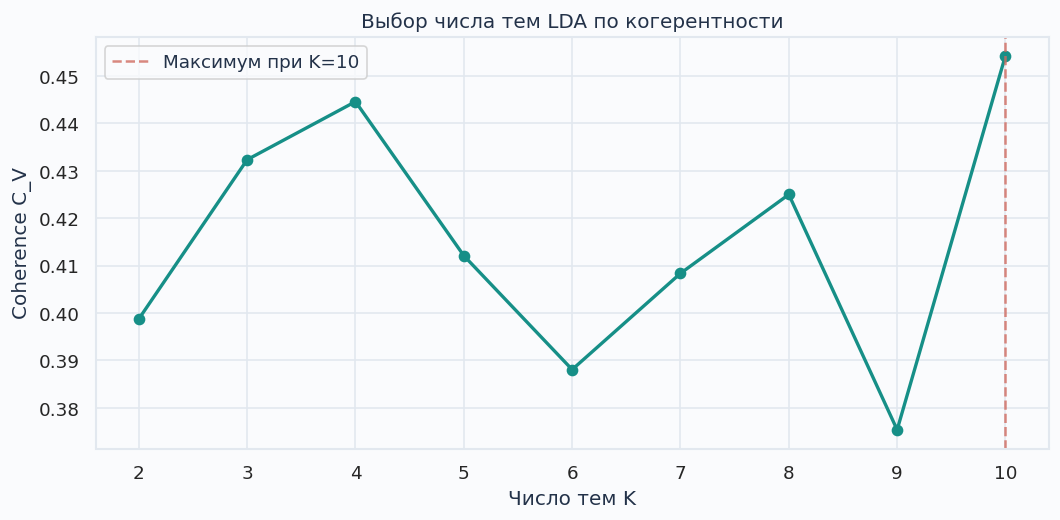

In [123]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(coherence_df["K"], coherence_df["C_V"], marker="o", lw=2, color=TEAL)
ax.axvline(best_k, ls="--", color=CORAL, alpha=0.8,
           label=f"Максимум при K={best_k}")
ax.set(xlabel="Число тем K", ylabel="Coherence C_V",
       title="Выбор числа тем LDA по когерентности")
ax.set_xticks(K_VALUES)
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "lda_coherence_cv.png", dpi=180, bbox_inches="tight")
plt.show()

#### Достаточно ли ориентироваться только на максимум?

В сохранённом запуске лучшая когерентность среди проверенных значений была при **K=10 (`C_V=0,4543`)**. Но при **K=4 результат составил 0,4446** — совсем немного меньше.

Поэтому сравним ключевые слова обеих моделей. Возможно, четыре более понятные темы окажутся полезнее десяти, среди которых есть похожие или плохо объяснимые.

In [124]:
comparison_k = sorted(set([4, best_k]))
for k in comparison_k:
    print(f"\nМодель с K={k}")
    for topic_id in range(k):
        terms = [term for term, _ in lda_models[k].show_topic(topic_id, topn=7)]
        print(f"  Тема {topic_id + 1}: {', '.join(terms)}")


Модель с K=4
  Тема 1: remote, headphones, app, batteries, box, like, stick
  Тема 2: kindle, screen, cover, read, case, like, new
  Тема 3: echo, great, tap, sound, alexa, speaker, music
  Тема 4: tablet, hdx, kindle, year, apps, model, video

Модель с K=10
  Тема 1: model, year, fun, features, version, setup, lot
  Тема 2: screen, remote, phone, time, work, new, stick
  Тема 3: great, echo, tap, sound, speaker, good, music
  Тема 4: alexa, great, love, echo, dot, portability, music
  Тема 5: tablet, device, hdx, apps, prime, app, video
  Тема 6: kindle, cover, read, case, screen, like, new
  Тема 7: box, voice, remote, roku, streaming, push, search
  Тема 8: months, design, lasted, stereo, ago, longer, daily
  Тема 9: item, enjoy, christmas, provided, stock, waste, worth
  Тема 10: remote, headphones, batteries, working, like, volume, outside


**Небольшое ограничение эксперимента.** Мы проверяем только `K=2…10`. Если максимум оказался при десяти темах, нельзя утверждать, что лучшее число тем вообще равно десяти. Для проверки можно расширить диапазон до 15, но сначала посмотрим, насколько понятны уже найденные темы.

### Шаг 9. Что означают найденные темы

Для каждой темы покажем десять самых весомых слов, подберём короткое название и опишем, что их объединяет. Дополнительно посмотрим на отзыв, в котором тема выражена сильнее всего: одних слов иногда недостаточно, чтобы понять, о чём она.

Ниже предварительные названия тем из предыдущего запуска с `K=10`. Это не готовые эталонные метки: если переобучить LDA, порядок и состав тем могут измениться. Там, где слова плохо сочетаются друг с другом, так и напишем — не будем придумывать уверенное название любой ценой.

In [125]:
MANUAL_TOPIC_TITLES_K10 = {
    0: "Версии устройств и соотношение цены и возможностей",
    1: "Экран и устройства управления (смешанная)",
    2: "Звук и портативные колонки",
    3: "Alexa, Echo и голосовой помощник",
    4: "Планшеты, приложения и медиаконтент",
    5: "Kindle: чтение, экран и чехлы",
    6: "Стриминг и голосовые пульты",
    7: "Срок службы и дизайн (неоднозначная)",
    8: "Покупки, подарки и общая оценка (неоднозначная)",
    9: "Пульты, наушники и аксессуары (смешанная)",
}

In [126]:
MANUAL_TOPIC_EXPLANATIONS_K10 = {
    0: "Отзывы о разных моделях устройств, их новых функциях и том, насколько покупка оправдывает свою стоимость.",
    1: "Обсуждаются экраны, телефоны, пульты и защитные аксессуары. Слова относятся к разным устройствам, поэтому тема получилась неоднородной.",
    2: "Отзывы об устройствах Echo и Tap. Пользователи обсуждают качество звука, прослушивание музыки и удобство использования колонок.",
    3: "Отзывы об Alexa и умных колонках Echo Dot. Основное внимание уделяется голосовому управлению, функциям и удобству устройств.",
    4: "Обсуждаются планшеты Fire, приложения, просмотр видео и сервисы Amazon. Также встречаются отзывы об ограничениях программного обеспечения.",
    5: "Отзывы о Kindle и Paperwhite. Пользователи обсуждают удобство чтения, качество экрана и защитные чехлы.",
    6: "Отзывы о стриминговых приставках, в том числе Roku. Пользователи оценивают поиск контента, голосовые команды и удобство просмотра.",
    7: "Встречаются отзывы о дизайне устройств и сроке их использования. Однако ключевые слова слабо связаны между собой, поэтому выделить одну тему сложно.",
    8: "Часть отзывов связана с покупками и подарками. При этом ключевые слова довольно разнородные, поэтому однозначно определить тему не получается.",
    9: "Обсуждаются различные аксессуары, включая пульты и наушники. Тема объединяет несколько категорий товаров и не имеет чёткой направленности.",
}

Если после запуска число тем или наборы ключевых слов изменились, старые названия могут перестать подходить. В таком случае оставим пометку для повторного просмотра, а не будем автоматически присваивать прежнее описание.

In [127]:
EXPECTED_TOPIC_ANCHORS_K10 = {
    0: {"model", "year", "features", "value"},
    1: {"screen", "remote", "phone", "protector"},
    2: {"echo", "tap", "sound", "speaker"},
    3: {"alexa", "echo", "dot", "portability"},
    4: {"tablet", "hdx", "apps", "prime"},
    5: {"kindle", "cover", "read", "paperwhite"},
    6: {"box", "voice", "remote", "roku"},
    7: {"months", "design", "lasted", "stereo"},
    8: {"item", "enjoy", "christmas", "stock"},
    9: {"remote", "headphones", "batteries", "volume"},
}

In [128]:
representatives = {topic_id: (None, -1.0) for topic_id in range(best_k)}
for pos in nonempty_positions:
    weights = best_lda.get_document_topics(lda_corpus[pos], minimum_probability=0.0)
    for topic_id, probability in weights:
        if probability > representatives[topic_id][1]:
            representatives[topic_id] = (pos, probability)

In [129]:
topics_rows = []
for topic_id in range(best_k):
    weighted = best_lda.show_topic(topic_id, topn=10)
    pos, probability = representatives[topic_id]
    current_words = {word for word, _ in weighted}
    same_topic = (best_k == 10 and
                  len(current_words & EXPECTED_TOPIC_ANCHORS_K10[topic_id]) >= 2)
    title = (MANUAL_TOPIC_TITLES_K10[topic_id] if same_topic
             else "Тема: требуется ручное название")
    explanation = (MANUAL_TOPIC_EXPLANATIONS_K10[topic_id] if same_topic
                   else "Ключевые слова изменились: требуется новая ручная интерпретация")
    topics_rows.append({"Тема": topic_id + 1, "Название": title,
                        "Топ-10 слов (вес)": ", ".join(f"{w} ({p:.3f})" for w,p in weighted),
                        "Интерпретация": explanation,
                        "Пример doc_id": frame.iloc[pos]["doc_id"] if pos is not None else "",
                        "Доля темы": round(float(probability), 3),
                        "Пример отзыва": frame.iloc[pos]["Text"] if pos is not None else ""})

In [130]:
summary_topics = pd.DataFrame(topics_rows)
display(summary_topics[["Тема", "Название", "Топ-10 слов (вес)",
                        "Интерпретация", "Пример doc_id"]])
summary_topics.to_csv(RESULTS_DIR / "lda_topics_interpretation.csv",
                      index=False, encoding="utf-8-sig")

,Тема,Название,Топ-10 слов (вес),Интерпретация,Пример doc_id
0,1,Версии устройств и соотношение цены и возможностей,"model (0.038), year (0.035), fun (0.032), features (0.025), version (0.021), setup (0.017), lot (0.017), getting (0.016), shipped (0.014), value (0.013)","Отзывы о разных моделях устройств, их новых функциях и том, насколько покупка оправдывает свою стоимость.",review_00180
1,2,Экран и устройства управления (смешанная),"screen (0.021), remote (0.020), phone (0.019), time (0.015), work (0.014), new (0.013), stick (0.012), replacement (0.011), protector (0.011), love (0.010)","Обсуждаются экраны, телефоны, пульты и защитные аксессуары. Слова относятся к разным устройствам, поэтому тема получилась неоднородной.",review_00235
2,3,Звук и портативные колонки,"great (0.048), echo (0.046), tap (0.046), sound (0.044), speaker (0.035), good (0.027), music (0.027), use (0.023), button (0.020), portable (0.019)","Отзывы об устройствах Echo и Tap. Пользователи обсуждают качество звука, прослушивание музыки и удобство использования колонок.",review_00105
3,4,"Alexa, Echo и голосовой помощник","alexa (0.106), great (0.032), love (0.031), echo (0.029), dot (0.026), portability (0.021), music (0.019), use (0.019), time (0.019), tap (0.019)","Отзывы об Alexa и умных колонках Echo Dot. Основное внимание уделяется голосовому управлению, функциям и удобству устройств.",review_00286
4,5,"Планшеты, приложения и медиаконтент","tablet (0.029), device (0.018), hdx (0.017), apps (0.016), prime (0.015), app (0.012), video (0.011), google (0.011), content (0.011), ipad (0.009)","Обсуждаются планшеты Fire, приложения, просмотр видео и сервисы Amazon. Также встречаются отзывы об ограничениях программного обеспечения.",review_00214
5,6,"Kindle: чтение, экран и чехлы","kindle (0.045), cover (0.024), read (0.019), case (0.018), screen (0.017), like (0.014), new (0.012), reading (0.011), paperwhite (0.011), books (0.011)","Отзывы о Kindle и Paperwhite. Пользователи обсуждают удобство чтения, качество экрана и защитные чехлы.",review_00522
6,7,Стриминг и голосовые пульты,"box (0.048), voice (0.044), remote (0.041), roku (0.038), streaming (0.023), push (0.022), search (0.021), know (0.020), gaming (0.019), apple (0.018)","Отзывы о стриминговых приставках, в том числе Roku. Пользователи оценивают поиск контента, голосовые команды и удобство просмотра.",review_00060
7,8,Срок службы и дизайн (неоднозначная),"months (0.035), design (0.030), lasted (0.025), stereo (0.018), ago (0.018), longer (0.017), daily (0.017), supposed (0.016), basis (0.016), sling (0.015)","Встречаются отзывы о дизайне устройств и сроке их использования. Однако ключевые слова слабо связаны между собой, поэтому выделить одну тему сложно.",review_00096
8,9,"Покупки, подарки и общая оценка (неоднозначная)","item (0.100), enjoy (0.096), christmas (0.040), provided (0.027), stock (0.027), waste (0.022), worth (0.020), totally (0.017), request (0.017), beats (0.014)","Часть отзывов связана с покупками и подарками. При этом ключевые слова довольно разнородные, поэтому однозначно определить тему не получается.",review_00248
9,10,"Пульты, наушники и аксессуары (смешанная)","remote (0.064), headphones (0.035), batteries (0.023), working (0.022), like (0.020), volume (0.018), outside (0.014), pair (0.013), use (0.013), set (0.010)","Обсуждаются различные аксессуары, включая пульты и наушники. Тема объединяет несколько категорий товаров и не имеет чёткой направленности.",review_00467


Прочитаем по одному показательному отзыву для каждой темы. Так можно проверить, действительно ли название соответствует содержанию, а не только нескольким словам из списка.

In [131]:
for row in topics_rows:
    print("\n", "="*65)
    print("Тема", row["Тема"], "—", row["Название"])
    print("Ключевые слова:", row["Топ-10 слов (вес)"])
    print("Пример отзыва:", str(row["Пример отзыва"])[:700])


Тема 1 — Версии устройств и соотношение цены и возможностей
Ключевые слова: model (0.038), year (0.035), fun (0.032), features (0.025), version (0.021), setup (0.017), lot (0.017), getting (0.016), shipped (0.014), value (0.013)
Пример отзыва: I'm writing this review with the benefit of being an experienced Kindle Fire user vs. someone brand new to the Kindle family. In summary, for 139 you are getting a good deal on a tablet computer - especially if you compare it to the 500 or more you can spend on a Wi-Fi version of the iPad. Overall, if you consider the price and the functionality I think this is a great tool / toy if you watch a lot of video or play a lot of games on your device: the video quality is outstanding and you can really tell a difference between this and last year's Fire. If you are a first-time tablet buyer, where price vs. value is a key consideration, or if you are looking for an affordable tablet for the kids, 

Тема 2 — Экран и устройства управления (смешанная)
Кл

#### Какие темы встречаются чаще

Посмотрим, какая тема преобладает в каждом отзыве, и подсчитаем количество таких документов. Это помогает понять, не получилась ли одна большая тема и несколько совсем маленьких.

In [132]:
dominant_topics = []
for bow_doc in nonempty_corpus:
    weights = best_lda.get_document_topics(bow_doc, minimum_probability=0.0)
    dominant_topics.append(max(weights, key=lambda item: item[1])[0] + 1)
topic_counts = pd.Series(dominant_topics).value_counts().reindex(
    range(1, best_k + 1), fill_value=0)

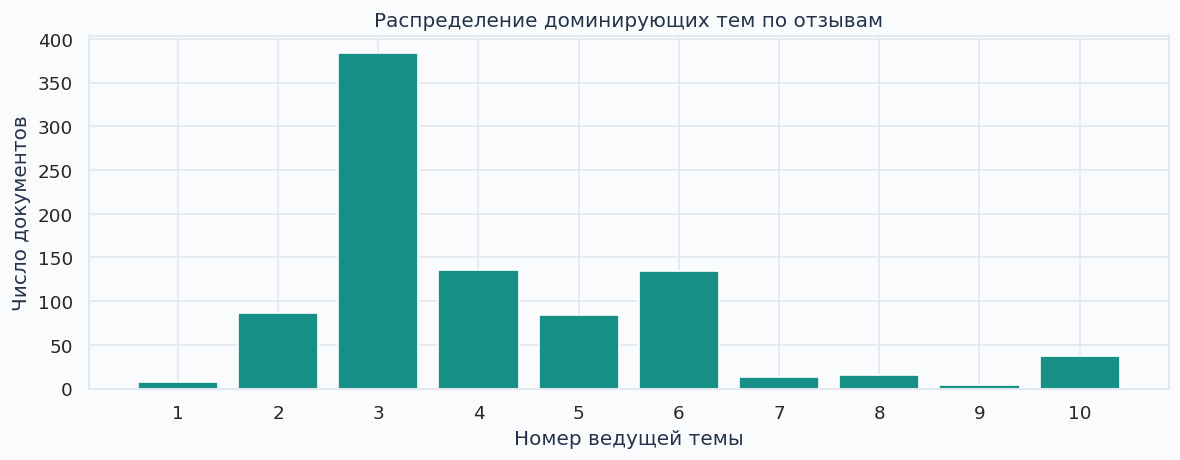

In [133]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(topic_counts.index.astype(str), topic_counts.values, color=TEAL)
ax.set(xlabel="Номер ведущей темы", ylabel="Число документов",
       title="Распределение доминирующих тем по отзывам")
fig.tight_layout()
fig.savefig(FIG_DIR / "lda_dominant_topics.png", dpi=180, bbox_inches="tight")
plt.show()

#### Выводы по LDA

Лучше всего удалось выделить темы, связанные с **колонками и качеством звука**, **Alexa и Echo**, **приложениями на планшетах**, **чтением на Kindle** и **приставками для просмотра видео**.

Некоторые группы получились менее понятными: например, слова `months`, `design`, `stereo` или `item`, `enjoy`, `christmas` не складываются в одну очевидную тему. Это нормально для тематического моделирования, и мы отмечаем такие случаи отдельно.

В итоге выбирать число тем стоит не только по максимальному `C_V`, но и по тому, насколько легко объяснить результаты на реальных отзывах.

### Шаг 10. Проверка и сохранение результатов

В конце убедимся, что размерности данных согласованы, метрики корректны, индекс не пустой, а число тем выбрано из проверенного диапазона. Сохраним таблицы, графики и параметры запуска.

In [134]:
assert len(frame) == len(term_freqs) == len(doc_lengths)
assert avgdl > 0 and len(inverted_index) > 0
assert set(y_train.unique()) == set(y_test.unique()) == set(LABELS)
assert all(col in metrics_table for col in ["Macro Precision", "Macro Recall", "Macro F1"])
assert best_k in K_VALUES and len(topics_rows) == best_k
assert (metrics_table["Macro F1"].between(0, 1)).all()
print("Контрольные проверки выполнены")

Контрольные проверки выполнены


In [135]:
manifest = {
    "data_source": str(csv_path), "original_rows": int(len(raw)),
    "clean_corpus_rows": int(len(frame)),
    "class_distribution": {k: int(v) for k,v in frame["Sentiment"].value_counts().items()},
    "train_rows": int(len(train_df)), "test_rows": int(len(test_df)),
    "classifiers": list(model_specs), "selected_by_train_cv": selected_model_name,
    "k_selected_by_cv_coherence": best_k, "k_values": K_VALUES,
    "random_state": SEED,
    "note": "Topic titles are provisional; evaluate manually after rerun."
}
(RESULTS_DIR / "run_manifest.json").write_text(
    json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")

651

In [136]:
print("Все результаты сохранены в:", RESULTS_DIR.resolve())
for path in sorted(RESULTS_DIR.rglob("*")):
    if path.is_file():
        print("  ", path.relative_to(RESULTS_DIR))

Все результаты сохранены в: C:\Users\sonyb\Jupyter\textAnalysis\lab3\results_lab3
   bm25_top5.csv
   classification_metrics.csv
   corpus.csv
   excluded_conflicts.csv
   figures\class_distribution.png
   figures\confusion_matrices.png
   figures\lda_coherence_cv.png
   figures\lda_dominant_topics.png
   five_errors_for_review.csv
   inverted_index_summary.csv
   lda_coherence.csv
   lda_topics_interpretation.csv
   run_manifest.json
   vector_dimensions.csv


#### Общие выводы

**1. Векторизация.** Мы построили BoW и TF-IDF. Оба способа использовали словарь, собранный только по обучающим отзывам. При одинаковых настройках размерность совпала, но веса признаков отличались.

**2. Классификация.** Обучили Logistic Regression и Linear SVM с учётом дисбаланса. Сравнили их по Macro F1 и проверили на отложенной тестовой выборке. Для наших данных Macro F1 лучше отражает качество, чем одна Accuracy.

**3. Анализ ошибок.** Рассмотрели пять случаев, в которых прогноз не совпал с меткой. Часть сложностей связана со смешанными оценками и короткими отзывами. А часть с тем, что мы получили классы из оценок покупателей, а не из ручной разметки тональности.

**4. Поиск.** Построили инвертированный индекс и поиск BM25. Он находит тексты по словам запроса и показывает пять лучших совпадений, но не всегда понимает, положительный или отрицательный смысл имеет найденный фрагмент.

**5. Темы.** Обучили LDA, сравнили несколько значений K по когерентности и попытались описать полученные темы по ключевым словам и примерам отзывов. Не все группы вышли однородными.